# Salary Prediction Using Linear Regression


## 1. Importing Libraries


In [1]:
import torch
from matplotlib import pyplot as plt

## 2. Preparing and Visualizing Salary Data


Text(0, 0.5, 'salary')

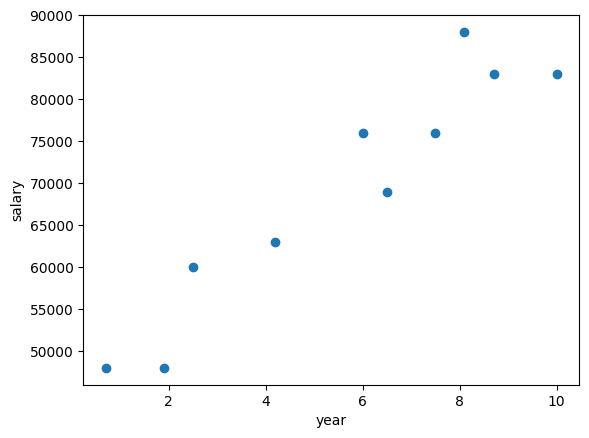

In [2]:
salary_and_year = [[83000, 8.7],
                  [88000, 8.1],
                  [48000, 0.7],
                  [76000, 6],
                  [69000, 6.5],
                  [76000, 7.5],
                  [60000, 2.5],
                  [83000, 10],
                  [48000, 1.9],
                  [63000, 4.2]]

data = torch.Tensor(salary_and_year)
salaries = data[:, 0]
years = data[:, 1]
plt.scatter(years, salaries)
plt.xlabel('year')
plt.ylabel('salary')

## 3. Training the Linear Regression Model


In [3]:
from torch.nn import Linear, MSELoss
from torch.optim import Adam

year2salary = Linear(1, 1)
mse = MSELoss()

optimizer = Adam(year2salary.parameters(), lr=1e+2)

years_train = years.reshape([-1, 1])
salaries_train = salaries.reshape([-1, 1])

for i in range(1000):
    salaries_estimate = year2salary(years_train)
    loss = mse(salaries_estimate, salaries_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

def estimate(func, inputs):
    return [
        func(torch.Tensor([x]).reshape([1, 1])).item()
        for x in inputs
    ]

## 4. Visualizing Predictions and Estimating Salary


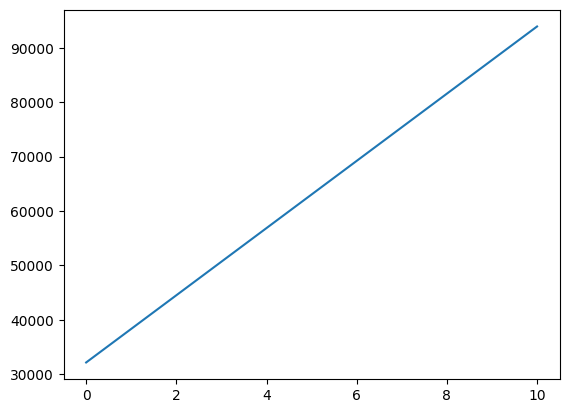

salary at 5: 63043.33203125
student id: 2024XXXXXX
name: 한서현


In [4]:
zero_ten = [0, 10]
estimates_zero_ten = estimate(year2salary, zero_ten)
plt.plot(zero_ten, estimates_zero_ten)
plt.show()
estimate_five = estimate(year2salary, [5])[0]
print(f'salary at 5: {estimate_five}')
print('student id: 2024XXXXXX')
print('name: 한서현')